# 02. 희소 오토인코더(SAE)로 ESM-2 은닉 상태 해석하기 — 특징이 정말 "개념"을 가리키는가?

**등급**: 🟢 Mac 로컬 (MPS) · Colab T4에서도 실행 확인(약 13분) · **예상 시간**: 약 14분 (ESM-2 35M 두 번 통과 약 5.5분 + SAE 학습 2분 + 부트스트랩·안정성 점검) · **다운로드**: 없음 (모듈 05의 UniProt 표와 모듈 02의 ESM-2 35M 캐시를 쓴다)

**질문**: ESM-2 은닉 상태의 개별 차원은 여러 개념이 섞인 **polysemantic**이라는 가설이 있다(superposition). 은닉 상태를 더 넓은 사전으로 **희소하게** 재구성하는 SAE를 학습하면, 개별 특징이 UniProt 키워드(예: Transmembrane, Zinc, Nucleus) 같은 **알려진 개념**을 더 잘 가리키는가? 선택 효과(수천 개 중 최선을 고르면 우연히도 좋아 보인다)를 빼도 그런가?

**설계 (결과를 보기 전에 정한 것)**
- 데이터: 모듈 05와 같은 UniProt 사람 reviewed 단백질(글자까지 같은 서열은 첫 행만; 약 7,397개), 개념 라벨 = UniProt `Keywords`(단백질 단위 이진). 분할: 모듈 05와 같은 **Pfam 연결 요소 묶음** 5-fold 중 폴드 0을 test로(약 20%), 나머지를 train(SAE 학습·특징 선택)으로 쓴다. 같은 Pfam 가족이 train·test에 걸치지 않는다.
- 활성: ESM-2 35M(12층)의 **층 6**(중간)과 **층 12**(마지막). `hidden_states[12]`는 `last_hidden_state`와 정확히 같아 최종 LayerNorm을 거친 값이고 층 6은 중간 블록의 출력이라 스케일이 다르다(SAE 입력은 층마다 평균 노름으로 정규화). 학습 잔기 벡터: train 단백질마다 무작위 64개 잔기(특수 토큰 제외).
- SAE(Gao et al. 2024의 TopK 형태): 인코더 $z=\mathrm{TopK}(\mathrm{ReLU}(W_e(x-b_d)+b_e))$, 디코더 $\hat x=W_d z+b_d$(열 단위 정규화), 사전 크기 $F=8d=3{,}840$, $k=32$, 손실 MSE. 입력은 평균 노름이 $\sqrt d$가 되도록 스케일.
- 단백질 수준 특징: 특징마다 **잔기에 걸친 max**와 **mean** 두 가지 집계. 키워드마다 train에서 AUROC가 가장 높은 (특징, 집계)를 고르고 **test 단백질에서** AUROC를 잰다. 키워드는 train 양성 ≥ 60, test 양성 ≥ 20인 것만(`Reference proteome` 제외; test 양성 수는 AUROC가 불안정해지는 키워드를 거르는 기준이며 test 라벨에 의존하지만 모든 방법에 똑같이 적용된다).
- 비교는 같은 선택 절차를 쓰지만 **후보 수와 방향 규칙은 다르다.** 원래 차원·PCA는 480 × {max, mean}에 양방향을 허용하고, SAE·무작위 사전은 3,840 × {max, mean}에 양의 방향만 허용한다. 무작위 사전이 SAE와 후보 수·규칙을 맞춘 선택 효과 대조군이다. 비교 대상은 **원래 차원 480개**(부호 양쪽 허용), **PCA 480성분**(부호 양쪽 허용), **훈련하지 않은 무작위 TopK 사전**(같은 구조, 선택 효과의 대조군), **SAE**(부호는 양의 방향만 허용; "개념이 있을 때 켜지는 특징")다. 참고로 평균 임베딩 위의 **로지스틱 회귀**(지도 상한 비슷한 것)도 둔다.
- 사전 지정한 주 비교: 키워드별 test AUROC의 중앙값, SAE − 원래 차원, SAE − 무작위 사전. 구간은 **Pfam 그룹 단위 부트스트랩**(조건부: 특징 선택은 고정).

> 키워드 라벨의 일부는 서열 유사성으로 옮겨 붙인 주석이고, SAE는 학습 단백질의 잔기만 본다. "해석 가능"은 **상관**이지 모델이 그 개념을 *사용*한다는 인과 증거가 아니다. 인과는 개입(ablation)이 필요하다(과제 4).

In [1]:
import gc
import gzip
import importlib.metadata as md
import math
import os
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
CACHE = (ROOT / ".cache") if ROOT is not None else Path("cache")
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
TSV = CACHE / "uniprot" / "human_reviewed_len80_400.tsv.gz"
assert TSV.exists(), f"{TSV} 가 없다 — 모듈 05 노트북 02를 먼저 실행해 UniProt 표를 받아 둘 것"

import torch
import torch.nn as nn
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, EsmModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
print("device:", DEVICE, "| cache:", CACHE)
print({k: md.version(k) for k in ["numpy", "pandas", "scikit-learn", "torch", "transformers"]})

W1110 13:05:48.407000 8109 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | cache: <repo>/.cache
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'transformers': '5.22.1'}


## 1. 데이터, 분할, 키워드
모듈 05와 같은 정리: 글자까지 같은 서열은 첫 행만 남기고, Pfam 도메인을 하나라도 공유하는 단백질을 같은 그룹으로 묶는다(연결 요소). 폴드 0이 test.

In [2]:
df = pd.read_csv(TSV, sep="\t")
df.columns = ["acc", "name", "gene", "length", "seq", "func", "kw", "pfam", "interpro"]
df = df[~df.seq.duplicated(keep="first")].reset_index(drop=True)
N = len(df)
pf = df["pfam"].fillna("").str.strip(";").str.split(";")
pf_ids = {p: i for i, p in enumerate(sorted({p for x in pf for p in x if p}))}
r_, c_ = zip(*[(i, pf_ids[p]) for i, x in enumerate(pf) for p in set(x) if p])
M = sparse.csr_matrix((np.ones(len(r_)), (r_, c_)), shape=(N, len(pf_ids)))
_, GROUP = connected_components((M @ M.T) > 0, directed=False)


def group_fold0(K=5, seed=0):
    rng = np.random.default_rng(seed)
    u, inv = np.unique(GROUP, return_inverse=True)
    sizes = np.bincount(inv)
    order = np.lexsort((rng.random(len(u)), -sizes))
    load, assign = np.zeros(K), np.zeros(len(u), int)
    for g in order:
        f = int(np.argmin(load))
        assign[g] = f
        load[f] += sizes[g]
    fo = assign[inv]
    return np.where(fo != 0)[0], np.where(fo == 0)[0]


TR, TE = group_fold0()
assert not set(GROUP[TR]) & set(GROUP[TE])
KW = df.kw.fillna("").str.split(";").map(lambda x: {k.strip() for k in x if k.strip()})
kw_all = pd.Series([k for s in KW for k in s]).value_counts()
KEYWORDS = []
for k in kw_all.index:
    if k == "Reference proteome":
        continue
    y = np.array([k in s for s in KW])
    if y[TR].sum() >= 60 and y[TE].sum() >= 20:
        KEYWORDS.append(k)
Y = {k: np.array([k in s for s in KW]) for k in KEYWORDS}
print(f"단백질 {N}개 | train {len(TR)} / test {len(TE)} (공유 Pfam 그룹 0) | 키워드 {len(KEYWORDS)}개 (train 양성 ≥60, test 양성 ≥20)")
print("예:", KEYWORDS[:12])

단백질 7397개 | train 5917 / test 1480 (공유 Pfam 그룹 0) | 키워드 83개 (train 양성 ≥60, test 양성 ≥20)
예: ['Proteomics identification', '3D-structure', 'Membrane', 'Alternative splicing', 'Phosphoprotein', 'Transmembrane', 'Transmembrane helix', 'Cytoplasm', 'Nucleus', 'Disulfide bond', 'Glycoprotein', 'Cell membrane']


## 2. ESM-2 35M 활성 수집 (1차 통과): train 단백질의 잔기 샘플
층 6과 층 12(`hidden_states[6]`, `hidden_states[12]`). 패딩·`<cls>`·`<eos>`를 제외한 잔기에서 단백질당 최대 64개를 무작위로 뽑는다.

In [3]:
ESM_REPO, ESM_REV = "facebook/esm2_t12_35M_UR50D", "6fbf070e65b0b7291e7bbcd451118c216cff79d8"
ESM_DIR = Path(snapshot_download(ESM_REPO, revision=ESM_REV, allow_patterns=["model.safetensors", "*.json", "vocab.txt"]))
TOK = AutoTokenizer.from_pretrained(ESM_DIR)
ESM = EsmModel.from_pretrained(ESM_DIR, add_pooling_layer=False).eval().to(DEVICE)
LAYERS = [6, 12]
D = ESM.config.hidden_size


@torch.no_grad()
def run_batches(idx, fn, batch=32):
    """idx 단백질을 길이 순으로 묶어 ESM을 통과시키고, 배치마다 fn(ix, hidden_states[LAYERS], 잔기 마스크)를 호출한다."""
    order = idx[np.argsort(df.length.values[idx])]
    for s in range(0, len(order), batch):
        ix = order[s:s + batch]
        enc = TOK(df.seq.values[ix].tolist(), return_tensors="pt", padding=True).to(DEVICE)
        hs = ESM(**enc, output_hidden_states=True).hidden_states
        m = enc["attention_mask"].clone()
        last = m.sum(1) - 1
        m[:, 0] = 0
        m[torch.arange(len(ix)), last] = 0                       # <cls>, <eos> 제외 (패딩은 이미 0)
        fn(ix, [hs[l] for l in LAYERS], m.bool())
        del hs, enc
        if DEVICE.type == "mps":
            torch.mps.empty_cache()


rng = np.random.default_rng(SEED)
samples = {l: [] for l in LAYERS}


def collect(ix, hs, m):
    for b in range(len(ix)):
        pos = torch.where(m[b])[0].cpu().numpy()
        take = rng.choice(pos, size=min(64, len(pos)), replace=False)
        for l, h in zip(LAYERS, hs):
            samples[l].append(h[b, take].float().cpu().numpy())


t0 = time.time()
run_batches(TR, collect)
X = {l: np.concatenate(samples[l]) for l in LAYERS}
del samples
gc.collect()
print(f"1차 통과 {time.time() - t0:.0f}초 | 학습 잔기 벡터 {X[LAYERS[0]].shape} (층당 {X[LAYERS[0]].nbytes / 1e9:.2f} GB)")

1차 통과 130초 | 학습 잔기 벡터 (378688, 480) (층당 0.73 GB)


## 3. SAE 학습
- TopK SAE. 인코더/디코더를 같은 무작위 행렬로 시작하고 디코더 열은 매 스텝 단위 노름으로 되돌린다. **구현 단순화**: ReLU는 TopK 뒤에 적용했고, 디코더 열을 업데이트 *후* 정규화할 뿐 기울기의 디코더 방향 성분을 제거하는 투영은 하지 않았다(참고한 논문의 구현과 다를 수 있다†). $b_d$는 학습 데이터 평균으로 시작.
- Adam(lr 4e-4), 배치 4,096, 12 에폭. 지표: **FVU**(설명되지 않은 분산 비율, 낮을수록 좋음)와 **죽은 특징** 비율(2차 통과에서 모든 단백질의 **모든 잔기**에서 한 번도 켜지지 않은 특징; 단백질 수준 max로는 의미가 없었다)과 활성 밀도 분포.
- **무작위 사전**: 학습 없이 초기화만 한 같은 구조 → 선택 효과의 대조군.

In [4]:
class TopKSAE(nn.Module):
    def __init__(self, d, F, k, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        W = torch.randn(F, d, generator=g) / math.sqrt(d)
        self.W_enc, self.b_enc = nn.Parameter(W.clone()), nn.Parameter(torch.zeros(F))
        self.W_dec, self.b_dec = nn.Parameter(W.clone().T.contiguous()), nn.Parameter(torch.zeros(d))
        self.k = k
        self.normalize_decoder()

    @torch.no_grad()
    def normalize_decoder(self):
        self.W_dec.data /= self.W_dec.data.norm(dim=0, keepdim=True).clamp(min=1e-8)

    def encode(self, x):
        pre = (x - self.b_dec) @ self.W_enc.T + self.b_enc
        v, i = pre.topk(self.k, dim=-1)
        return torch.zeros_like(pre).scatter(-1, i, torch.relu(v))

    def decode(self, z):
        return z @ self.W_dec.T + self.b_dec


def train_sae(x, F=8 * D, k=32, epochs=12, bs=4096, lr=4e-4, seed=0):
    torch.manual_seed(seed)
    scale = math.sqrt(D) / np.linalg.norm(x, axis=1).mean()
    xt = torch.tensor(x * scale, dtype=torch.float32)
    sae = TopKSAE(D, F, k, seed).to(DEVICE)
    sae.b_dec.data = xt.mean(0).to(DEVICE)
    opt = torch.optim.Adam(sae.parameters(), lr=lr)
    n, var = len(xt), ((xt - xt.mean(0)) ** 2).sum(1).mean().item()
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(n)
        tot = 0.0
        for s in range(0, n, bs):
            xb = xt[perm[s:s + bs]].to(DEVICE)
            loss = ((sae.decode(sae.encode(xb)) - xb) ** 2).sum(1).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            sae.normalize_decoder()
            tot += loss.item() * len(xb)
        hist.append(tot / n / var)
    sae.eval()
    return sae, scale, hist


def fvu(sae, x, scale, n=50000):
    sub = np.random.default_rng(0).choice(len(x), size=min(n, len(x)), replace=False)             # 단백질 순서에 치우치지 않게 무작위 부분집합
    xt = torch.tensor(x[sub] * scale, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        err = ((sae.decode(sae.encode(xt)) - xt) ** 2).sum(1).mean().item()
    return err / ((xt - xt.mean(0)) ** 2).sum(1).mean().item()


SAES, RAND, STATS = {}, {}, []
t0 = time.time()
for l in LAYERS:
    sae, scale, hist = train_sae(X[l], seed=SEED)
    rsae = TopKSAE(D, 8 * D, 32, seed=123).to(DEVICE).eval()                    # 무작위 사전: 학습하지 않고 b_dec만 평균으로 둔다
    rsae.b_dec.data = torch.tensor(X[l].mean(0) * scale, dtype=torch.float32, device=DEVICE)
    SAES[l], RAND[l] = (sae, scale), (rsae, scale)
    STATS.append(dict(층=l, FVU_학습후=fvu(sae, X[l], scale), FVU_무작위사전=fvu(rsae, X[l], scale), 첫_에폭_FVU=hist[0], 마지막_에폭_FVU=hist[-1]))
    print(f"층 {l} SAE 학습 {time.time() - t0:.0f}초 (누적)")
print(pd.DataFrame(STATS).round(3).to_string(index=False))

# 두 번째 시드 (층 12만): 특징의 시드 간 안정성 점검용
sae2, scale2, _ = train_sae(X[12], seed=1)

층 6 SAE 학습 60초 (누적)


층 12 SAE 학습 119초 (누적)
 층  FVU_학습후  FVU_무작위사전  첫_에폭_FVU  마지막_에폭_FVU
 6    0.145      0.745     0.515       0.148
12    0.195      0.747     0.536       0.199


## 4. 단백질 수준 특징 계산 (2차 통과)
모든 단백질(train+test)에 대해 배치마다 (a) 원래 차원, (b) PCA 성분, (c) SAE, (d) 무작위 사전을 계산하고 잔기에 걸친 **max / mean**으로 집계한다. PCA는 층마다 학습 잔기 샘플의 상위 480성분.

In [5]:
PCA = {}
for l in LAYERS:
    sub = np.random.default_rng(SEED).choice(len(X[l]), size=min(200000, len(X[l])), replace=False)        # 단백질 순서에 치우치지 않게 무작위 20만 잔기
    xs = torch.tensor(X[l][sub], dtype=torch.float32)
    mu = xs.mean(0)
    _, _, V = torch.pca_lowrank(xs - mu, q=D, center=False, niter=4)
    PCA[l] = (mu.to(DEVICE), V.to(DEVICE))                                      # V: d×q

FEAT = {(m, l, a): None for m in ["raw", "pca", "sae", "rand"] for l in LAYERS for a in ["max", "mean"]}
dims = {"raw": D, "pca": D, "sae": 8 * D, "rand": 8 * D}
for key in FEAT:
    FEAT[key] = np.zeros((N, dims[key[0]]), np.float32)
DENS = {(m, l): np.zeros(8 * D) for m in ["sae", "rand"] for l in LAYERS}            # 특징별 활성 잔기 수 (전체 단백질)
NRES = [0]


def agg_batch(ix, hs, m):
    mf = m.float().unsqueeze(-1)
    cnt = mf.sum(1).clamp(min=1)
    NRES[0] += int(m.sum().item())
    for l, h in zip(LAYERS, hs):
        h = h.float()
        reps = {"raw": h, "pca": (h - PCA[l][0]) @ PCA[l][1]}
        sae, sc = SAES[l]
        rs, rsc = RAND[l]
        flat = h.reshape(-1, D)
        reps["sae"] = sae.encode(flat * sc).reshape(h.shape[0], h.shape[1], -1)
        reps["rand"] = rs.encode(flat * rsc).reshape(h.shape[0], h.shape[1], -1)
        for name, z in reps.items():
            if name in ("sae", "rand"):
                DENS[(name, l)] += ((z > 0) & m.unsqueeze(-1)).sum((0, 1)).cpu().numpy()
            mx = z.masked_fill(~m.unsqueeze(-1), -1e9).max(1).values
            FEAT[(name, l, "max")][ix] = mx.cpu().numpy()
            FEAT[(name, l, "mean")][ix] = ((z * mf).sum(1) / cnt).cpu().numpy()


@torch.no_grad()
def agg_wrapper(ix, hs, m):
    agg_batch(ix, hs, m)


t0 = time.time()
run_batches(np.arange(N), agg_wrapper, batch=16)
print(f"2차 통과 {time.time() - t0:.0f}초")
rows = []
for (name, l), cnt_ in DENS.items():
    dens = cnt_ / NRES[0]
    rows.append(dict(방법=name, 층=l, 죽은_특징_비율=float((cnt_ == 0).mean()), 밀도_하위1퍼센트=np.percentile(dens, 1), 밀도_중앙값=np.median(dens), 밀도_상위1퍼센트=np.percentile(dens, 99)))
print(f"잔기 {NRES[0]:,}개 기준 특징 활성 밀도 (TopK 이므로 평균 밀도는 k/F = {32 / (8 * D):.4f})")
print(pd.DataFrame(rows).round(5).to_string(index=False))
del ESM
gc.collect()
if DEVICE.type == "mps":
    torch.mps.empty_cache()

2차 통과 197초
잔기 1,893,297개 기준 특징 활성 밀도 (TopK 이므로 평균 밀도는 k/F = 0.0083)
  방법  층  죽은_특징_비율  밀도_하위1퍼센트  밀도_중앙값  밀도_상위1퍼센트
 sae  6       0.0    0.00049 0.00290    0.10662
 sae 12       0.0    0.00146 0.00434    0.08046
rand  6       0.0    0.00156 0.00692    0.02858
rand 12       0.0    0.00176 0.00659    0.03304


## 5. 키워드 ↔ 특징: train에서 고르고 test에서 잰다
- 각 방법·층마다 (특징 × {max, mean}) 후보의 train AUROC를 순위 기반으로 한꺼번에 계산하고(동점은 평균 순위), 키워드마다 가장 높은 후보를 고른다. 원래 차원·PCA는 부호를 뒤집어도 되고(`|AUROC−0.5|`가 큰 것), SAE·무작위 사전은 **양의 방향만** 쓴다.
- test AUROC는 고른 (특징, 집계)로 계산한다. 선택에 test를 쓰지 않았다.

In [6]:
def rank_cols(Fm):
    return rankdata(Fm, axis=0)


def auc_vec(R, y):
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (R[y].sum(0) - n1 * (n1 + 1) / 2) / (n1 * n0)


METHODS = ["raw", "pca", "sae", "rand"]
TWO_SIDED = {"raw": True, "pca": True, "sae": False, "rand": False}
SEL = {}                      # (method, layer, keyword) -> dict(score_te, auc_tr, auc_te, feat, agg)
t0 = time.time()
for l in LAYERS:
    for m in METHODS:
        cand = np.concatenate([FEAT[(m, l, "max")][TR], FEAT[(m, l, "mean")][TR]], axis=1)
        cand_te = np.concatenate([FEAT[(m, l, "max")][TE], FEAT[(m, l, "mean")][TE]], axis=1)
        R = rank_cols(cand)
        for k in KEYWORDS:
            a = auc_vec(R, Y[k][TR])
            crit = np.abs(a - 0.5) if TWO_SIDED[m] else a
            j = int(np.argmax(crit))
            sign = -1.0 if (TWO_SIDED[m] and a[j] < 0.5) else 1.0
            s_te = sign * cand_te[:, j]
            F_ = cand.shape[1] // 2                                                      # 앞 절반 = max 집계, 뒤 절반 = mean 집계
            SEL[(m, l, k)] = dict(score_te=s_te, auc_tr=float(a[j] if sign > 0 else 1 - a[j]), auc_te=float(roc_auc_score(Y[k][TE], s_te)), feat=j % F_, agg="max" if j < F_ else "mean")
print(f"선택·평가 {time.time() - t0:.0f}초")

# 참고: 평균 임베딩 위 로지스틱 회귀 (지도)
PROBE = {}
for l in LAYERS:
    Z = StandardScaler().fit(FEAT[("raw", l, "mean")][TR])
    for k in KEYWORDS:
        clf = LogisticRegression(C=0.05, max_iter=300).fit(Z.transform(FEAT[("raw", l, "mean")][TR]), Y[k][TR])
        PROBE[(l, k)] = float(roc_auc_score(Y[k][TE], clf.decision_function(Z.transform(FEAT[("raw", l, "mean")][TE]))))

선택·평가 19초


### 결과 — 키워드별 test AUROC의 중앙값 [Pfam 그룹 부트스트랩 95%]
모든 키워드에 대해 키워드별 AUROC를 구하고 중앙값을 취한다(B=200 재표본; 재표본에서 양성이 없는 키워드는 그 회차에서 제외).

In [7]:
B = 200
rng_b = np.random.default_rng(1)
u_g, inv_g = np.unique(GROUP[TE], return_inverse=True)
BW = np.stack([np.bincount(rng_b.integers(0, len(u_g), len(u_g)), minlength=len(u_g))[inv_g] for _ in range(B)]).astype(float)


def boot_auc(y, s):
    out = np.full(B, np.nan)
    for b in range(B):
        w = BW[b]
        yy = y
        if w[yy].sum() == 0 or w[~yy].sum() == 0:
            continue
        out[b] = roc_auc_score(yy, s, sample_weight=w)
    return out


BOOT = {}
t0 = time.time()
for l in LAYERS:
    for m in METHODS:
        BOOT[(m, l)] = np.stack([boot_auc(Y[k][TE], SEL[(m, l, k)]["score_te"]) for k in KEYWORDS])           # [kw, B]
print(f"부트스트랩 {time.time() - t0:.0f}초 | 재표본에서 AUROC를 계산할 수 없어 제외된 (키워드, 회차) 비율: {np.mean([np.isnan(v).mean() for v in BOOT.values()]):.4f}")


def med_ci(a):
    med = np.nanmedian(a, axis=0)
    return np.nanpercentile(med, [2.5, 97.5])


rows = []
for l in LAYERS:
    for m in METHODS:
        a = np.array([SEL[(m, l, k)]["auc_te"] for k in KEYWORDS])
        lo, hi = med_ci(BOOT[(m, l)])
        rows.append(dict(층=l, 방법=m, test_AUROC_중앙값=f"{np.median(a):.3f} [{lo:.3f}, {hi:.3f}]", 평균=a.mean(), train_AUROC_중앙값=np.median([SEL[(m, l, k)]["auc_tr"] for k in KEYWORDS])))
    a = np.array([PROBE[(l, k)] for k in KEYWORDS])
    rows.append(dict(층=l, 방법="로지스틱(지도, 참고)", test_AUROC_중앙값=f"{np.median(a):.3f}", 평균=a.mean(), train_AUROC_중앙값=np.nan))
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\n사전 지정한 주 비교: 키워드별 test AUROC 차이의 중앙값 [95%] / SAE가 더 높은 키워드 비율")
for l in LAYERS:
    for other in ["raw", "rand"]:
        d = np.array([SEL[("sae", l, k)]["auc_te"] - SEL[(other, l, k)]["auc_te"] for k in KEYWORDS])
        db = BOOT[("sae", l)] - BOOT[(other, l)]
        lo, hi = med_ci(db)
        print(f"  층 {l:2d}  SAE − {other:4s}: {np.median(d):+.3f} [{lo:+.3f}, {hi:+.3f}] | SAE 우위 {np.mean(d > 0):.2f} ({int((d > 0).sum())}/{len(d)})")

부트스트랩 111초 | 재표본에서 AUROC를 계산할 수 없어 제외된 (키워드, 회차) 비율: 0.0018
 층           방법       test_AUROC_중앙값    평균  train_AUROC_중앙값
 6          raw 0.631 [0.623, 0.679] 0.662            0.769
 6          pca 0.645 [0.623, 0.696] 0.675            0.748
 6          sae 0.678 [0.636, 0.720] 0.699            0.784
 6         rand 0.657 [0.627, 0.697] 0.669            0.760
 6 로지스틱(지도, 참고)                0.821 0.795              NaN
12          raw 0.664 [0.647, 0.693] 0.677            0.772
12          pca 0.665 [0.644, 0.692] 0.679            0.741
12          sae 0.701 [0.676, 0.721] 0.713            0.782
12         rand 0.663 [0.653, 0.693] 0.684            0.762
12 로지스틱(지도, 참고)                0.828 0.808              NaN

사전 지정한 주 비교: 키워드별 test AUROC 차이의 중앙값 [95%] / SAE가 더 높은 키워드 비율
  층  6  SAE − raw : +0.022 [+0.016, +0.053] | SAE 우위 0.64 (53/83)
  층  6  SAE − rand: +0.022 [+0.015, +0.049] | SAE 우위 0.70 (58/83)
  층 12  SAE − raw : +0.037 [+0.016, +0.056] | SAE 우위 0.63 (52/83)
  층 12  SAE − rand:

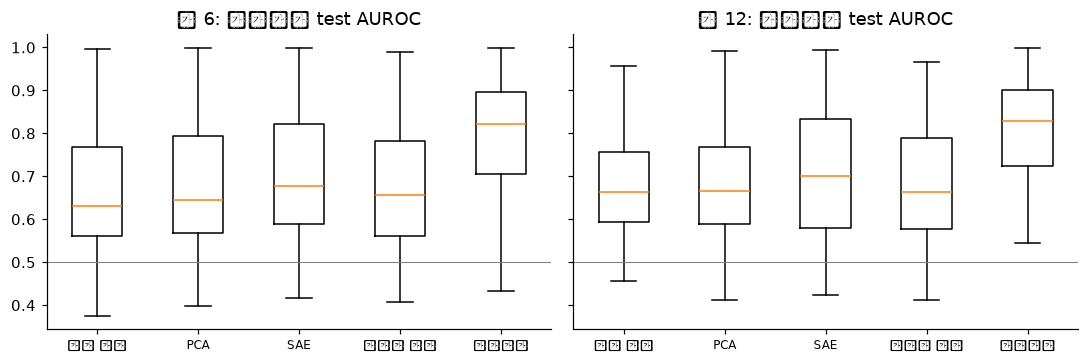

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, l in zip(axs, LAYERS):
    data = [[SEL[(m, l, k)]["auc_te"] for k in KEYWORDS] for m in METHODS] + [[PROBE[(l, k)] for k in KEYWORDS]]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels(["원래 차원", "PCA", "SAE", "무작위 사전", "로지스틱"], fontsize=8)
    ax.axhline(0.5, color="gray", lw=0.7)
    ax.set_title(f"층 {l}: 키워드별 test AUROC")
plt.tight_layout()
plt.show()

## 6. 시드 간 안정성, 그리고 특징을 눈으로 보기
(a) 같은 데이터에서 시드만 다르게 학습한 두 SAE(층 12)의 디코더 방향이 얼마나 대응되는가: 한 SAE의 각 특징에 대해 다른 SAE에서 가장 가까운 방향의 코사인(중앙값). 비교용으로 무작위 사전 두 개 사이의 값. (b) 몇 개 키워드의 최선 SAE 특징이 test 단백질에서 가장 크게 켜진 단백질 5개.

In [9]:
def decoder_dirs(s):
    W = s.W_dec.detach().float().cpu()
    return (W / W.norm(dim=0, keepdim=True)).T


A, A2 = decoder_dirs(SAES[12][0]), decoder_dirs(sae2)
RA, RB = decoder_dirs(RAND[12][0]), decoder_dirs(TopKSAE(D, 8 * D, 32, seed=7))
mx = lambda P, Q: (P @ Q.T).max(1).values
print("디코더 방향 최근접 코사인(중앙값) — 학습한 SAE 시드0 vs 시드1: %.3f | 무작위 사전 vs 무작위 사전: %.3f" % (mx(A, A2).median(), mx(RA, RB).median()))
print("시드 간 코사인 ≥ 0.9인 특징 비율: %.3f" % (mx(A, A2) >= 0.9).float().mean())

# 시드1 SAE로도 같은 키워드 선택·평가(층 12): 중앙값이 비슷한가
sc2 = scale2
agg2_max, agg2_mean = np.zeros((N, 8 * D), np.float32), np.zeros((N, 8 * D), np.float32)
ESM2 = EsmModel.from_pretrained(ESM_DIR, add_pooling_layer=False).eval().to(DEVICE)


@torch.no_grad()
def second_seed(ix, hs, m):
    h = hs[1].float()
    z = sae2.encode(h.reshape(-1, D) * sc2).reshape(h.shape[0], h.shape[1], -1)
    mf = m.float().unsqueeze(-1)
    agg2_max[ix] = z.masked_fill(~m.unsqueeze(-1), -1e9).max(1).values.cpu().numpy()
    agg2_mean[ix] = ((z * mf).sum(1) / mf.sum(1).clamp(min=1)).cpu().numpy()


ESM = ESM2
run_batches(np.arange(N), second_seed, batch=16)
cand = np.concatenate([agg2_max[TR], agg2_mean[TR]], axis=1)
cand_te = np.concatenate([agg2_max[TE], agg2_mean[TE]], axis=1)
R2_ = rank_cols(cand)
a2 = []
for k in KEYWORDS:
    a = auc_vec(R2_, Y[k][TR])
    j = int(np.argmax(a))
    a2.append(roc_auc_score(Y[k][TE], cand_te[:, j]))
print("시드1 SAE(층 12)의 키워드별 test AUROC 중앙값: %.3f (시드0: %.3f)" % (np.median(a2), np.median([SEL[("sae", 12, k)]["auc_te"] for k in KEYWORDS])))

디코더 방향 최근접 코사인(중앙값) — 학습한 SAE 시드0 vs 시드1: 0.312 | 무작위 사전 vs 무작위 사전: 0.162
시드 간 코사인 ≥ 0.9인 특징 비율: 0.008


시드1 SAE(층 12)의 키워드별 test AUROC 중앙값: 0.713 (시드0: 0.701)


In [10]:
order = sorted(KEYWORDS, key=lambda k: -SEL[("sae", 12, k)]["auc_te"])
for k in order[:5] + order[len(order) // 2:len(order) // 2 + 2] + order[-2:]:
    s = SEL[("sae", 12, k)]
    top = np.argsort(-s["score_te"])[:5]
    flags = "".join("+" if Y[k][TE][i] else "-" for i in top)
    print(f"[{k}] 특징 {s['feat']:4d}({s['agg']}) train {s['auc_tr']:.2f} → test {s['auc_te']:.2f} | 원래 차원 test {SEL[('raw', 12, k)]['auc_te']:.2f} | 무작위 사전 test {SEL[('rand', 12, k)]['auc_te']:.2f} | test 상위 5 단백질: " +
          ", ".join(str(df.gene.values[TE][i]) for i in top) + f" ({flags}; +는 키워드 보유)")

[GTP-binding] 특징 2564(mean) train 0.97 → test 0.99 | 원래 차원 test 0.95 | 무작위 사전 test 0.97 | test 상위 5 단백질: RHOG, CDC42, RHOB, RHOA, RHOC (+++++; +는 키워드 보유)
[Signal] 특징  989(mean) train 0.99 → test 0.99 | 원래 차원 test 0.80 | 무작위 사전 test 0.94 | test 상위 5 단백질: FDCSP, APOC1, DEFB132, NPPC, HAMP (+++++; +는 키워드 보유)
[Transmembrane helix] 특징  115(mean) train 0.98 → test 0.99 | 원래 차원 test 0.85 | 무작위 사전 test 0.93 | test 상위 5 단백질: TMEM216, LAPTM4A, MGST3, PET117, SNN (+++-+; +는 키워드 보유)
[Cleavage on pair of basic residues] 특징  560(mean) train 0.94 → test 0.98 | 원래 차원 test 0.90 | 무작위 사전 test 0.92 | test 상위 5 단백질: PMCH, ODAM, VIP, NPPA, GIP (+-+-+; +는 키워드 보유)
[Transmembrane] 특징 2973(mean) train 0.98 → test 0.98 | 원래 차원 test 0.85 | 무작위 사전 test 0.93 | test 상위 5 단백질: SLC35E3, SLC35D2, SLC35H1, SLC35C1, SLC35D1 (+++++; +는 키워드 보유)
[Endosome] 특징 1740(max) train 0.73 → test 0.70 | 원래 차원 test 0.46 | 무작위 사전 test 0.55 | test 상위 5 단백질: LAPTM4B, LAPTM4A, F3, IL10RB, CD244 (+----; +는 키워드 보유)
[Neurogenesis] 특징  516(m

## 정리
(실행 결과를 확인한 뒤 README §5에서 수치와 함께 해석한다. 이 노트북은 ESM-2 35M, 사람 단백질, UniProt 키워드, 한 번의 Pfam 묶음 분할, 사전 크기 3,840·k=32의 TopK SAE 한 설정(+시드 한 개 추가)에 대한 결과이며 InterPLM 같은 대규모 SAE의 결과를 대표하지 않는다. 특징–키워드 상관이 모델이 그 개념을 *사용*한다는 인과 증거가 아니다.)